# Part B (Rachel Sara Mathew, PES2UG24CS390)
## Baselines, ResNet-18 extension, evaluation, write-up and live demo
UE24CS352A Mini-Project, Section G, Team 7, Problem 75: Distracted Driver Detection

**Before you start:** Runtime > Change runtime type > **T4 GPU** > Save. Then Runtime > Run all, and allow Google Drive access when asked.

If Colab disconnects, just Run all again: finished models are skipped automatically.

## Step 1. Connect Google Drive and unpack the code
A pop-up asks for Drive permission: click **Connect to Google Drive** and allow.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

TEAM = '/content/drive/MyDrive/DDD_Team7'          # the shared folder
import os
assert os.path.exists(TEAM + '/distracted-driver-detection.zip'), 'Put distracted-driver-detection.zip inside MyDrive/DDD_Team7 first'
!rm -rf /content/distracted-driver-detection
!unzip -q -o "$TEAM/distracted-driver-detection.zip" -d /content
%cd /content/distracted-driver-detection
%env DDD_OUT=/content/drive/MyDrive/DDD_Team7/outputs
!pip -q install -r requirements.txt
print('Code ready. All results will be saved in MyDrive/DDD_Team7/outputs')

Mounted at /content/drive
/content/distracted-driver-detection
env: DDD_OUT=/content/drive/MyDrive/DDD_Team7/outputs
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 36.5 MB/s eta 0:00:00
Code ready. All results will be saved in MyDrive/DDD_Team7/outputs


## Step 2. Download the dataset from Kaggle (about 5 minutes)
Needs your Kaggle token saved in Colab Secrets (key icon on the left) under the name `KAGGLE_API_TOKEN`, with Notebook access switched on.

In [ ]:
import os
DATA_OK = '/content/data/imgs/train/c0'
DRIVE_ZIP = '/content/drive/MyDrive/DDD_Team7/statefarm_data.zip'   # optional pre-made copy of the dataset in Drive
if os.path.isdir(DATA_OK):
    print('Dataset already in /content/data, skipping download')
elif os.path.exists(DRIVE_ZIP):
    print('Using the dataset copy from Drive (no Kaggle needed)')
    !unzip -q -o "$DRIVE_ZIP" -d /content
else:
    from google.colab import userdata
    os.environ['KAGGLE_API_TOKEN'] = userdata.get('KAGGLE_API_TOKEN')
    !pip -q install -U kaggle
    !kaggle competitions download -c state-farm-distracted-driver-detection -p /content
    !unzip -q -o /content/state-farm-distracted-driver-detection.zip "imgs/train/*" "driver_imgs_list.csv" -d /content/data
    !rm -f /content/state-farm-distracted-driver-detection.zip
!ls /content/data /content/data/imgs/train

Using the dataset copy from Drive (no Kaggle needed)
/content/data:
driver_imgs_list.csv  imgs

/content/data/imgs/train:
c0  c1	c2  c3	c4  c5	c6  c7	c8  c9


If you see **401**, check the secret name and that Notebook access is on. If you see **403**, accept the competition rules on kaggle.com (Data tab > Download All) and run this cell again.

## Step 3. Resize all images to 64x64 and cache them (about 5 minutes)

Reading 22424 images and resizing to 64x64 (takes a few minutes) ...
Cached to /content/distracted-driver-detection/data/cache/statefarm_64.npz
X (22424, 64, 64, 3) y (22424,) distinct drivers 26
random  split: train 17939  val 4485  drivers in both sets: 26
driver  split: train 17446  val 4978  drivers in both sets: 0
Saved results/figures/samples.png and class_distribution.png


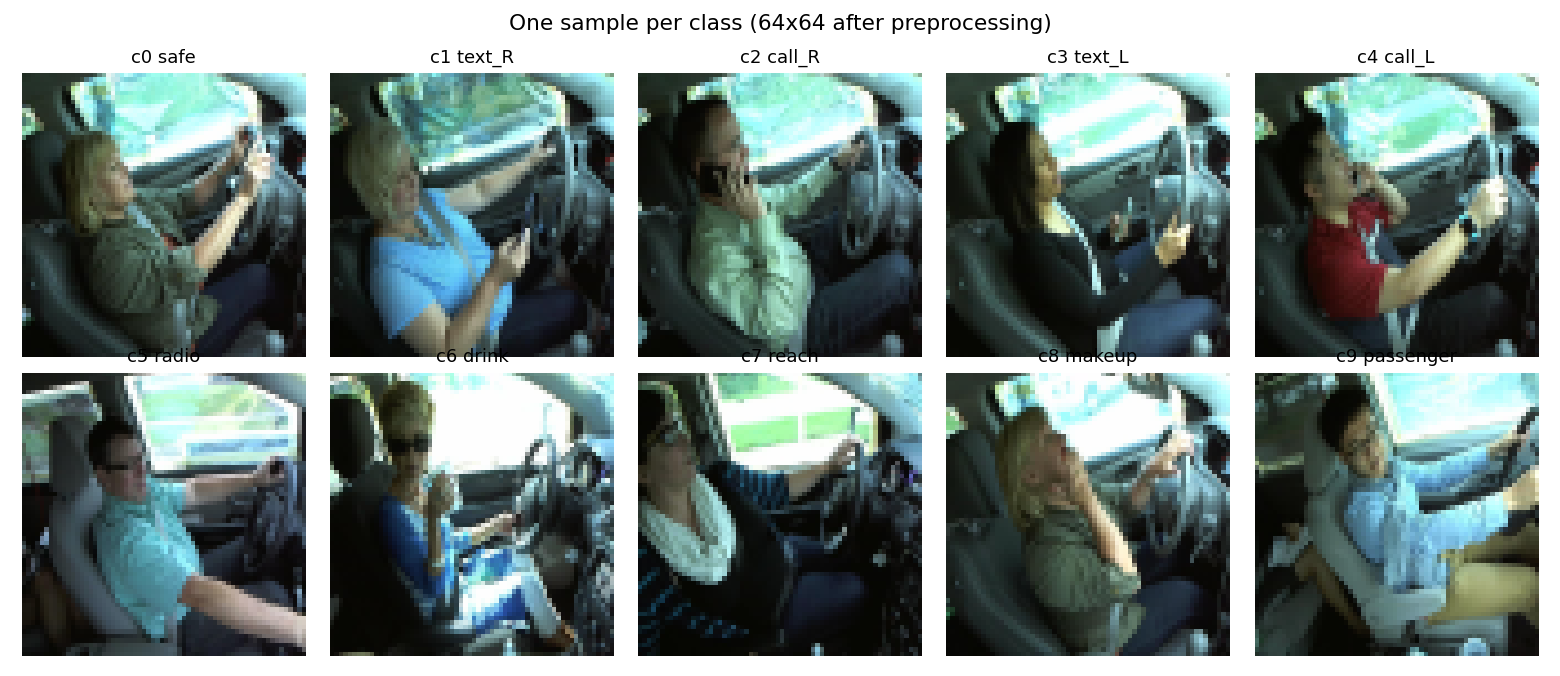

In [ ]:
!python -m src.data
from IPython.display import Image, display
display(Image('/content/drive/MyDrive/DDD_Team7/outputs/results/figures/samples.png'))

## Step 4. ResNet-18 transfer learning on both splits (GPU, about 30 to 45 minutes)
If this was interrupted (Colab disconnected), just run the cell again: a finished split prints `skip ... result already saved`, and only the unfinished split is retrained.

In [ ]:
!nvidia-smi -L
!python -m src.train_cnn --epochs 4

/bin/bash: line 1: nvidia-smi: command not found
  skip resnet18_transfer [random]: result already saved (use --force to retrain)
  skip resnet18_transfer [driver]: result already saved (use --force to retrain)


## Step 5. Naive Bayes and Decision Tree on both splits (the tree is slow: up to 30 to 60 minutes)

In [ ]:
!python -m src.train_sklearn

  skip naive_bayes [random]: result already saved (use --force to retrain)
  skip decision_tree [random]: result already saved (use --force to retrain)
  skip naive_bayes [driver]: result already saved (use --force to retrain)
  skip decision_tree [driver]: result already saved (use --force to retrain)


## Check Part B results
Prints train/validation accuracy for your three models (and the top confusions on the driver split, useful for your viva and slide 10).

In [ ]:
import json, glob
for f in sorted(glob.glob('/content/drive/MyDrive/DDD_Team7/outputs/results/*.json')):
    r = json.load(open(f))
    if r.get('model') in ('naive_bayes', 'decision_tree', 'resnet18_transfer'):
        print(f"{r['model']:18s} {r['split']:7s} train {100*r['train_acc']:.1f}%  val {100*r['val_acc']:.1f}%  macroF1 {100*r['val_macro_f1']:.1f}%")
        if r['split'] == 'driver':
            print('    top confusions:', [(c['true'], c['pred'], c['count']) for c in r['top_confusions'][:3]])

decision_tree      driver  train 100.0%  val 22.6%  macroF1 22.3%
    top confusions: [('drink', 'text_R', 130), ('text_R', 'passenger', 128), ('safe', 'call_R', 128)]
decision_tree      random  train 100.0%  val 89.3%  macroF1 89.1%
naive_bayes        driver  train 56.1%  val 27.6%  macroF1 25.9%
    top confusions: [('drink', 'call_R', 159), ('call_R', 'radio', 158), ('drink', 'radio', 140)]
naive_bayes        random  train 55.9%  val 54.5%  macroF1 54.4%
resnet18_transfer  driver  train 100.0%  val 91.5%  macroF1 90.9%
    top confusions: [('safe', 'passenger', 121), ('passenger', 'safe', 100), ('passenger', 'makeup', 62)]
resnet18_transfer  random  train 100.0%  val 99.8%  macroF1 99.8%


## Step 6. Save 20 demo images (drivers never seen in training) for the review day

In [ ]:
!python -m src.predict --export 20

Copied 20 images to /content/drive/MyDrive/DDD_Team7/outputs/demo_images


## Step 7. Comparison table, figures and the write-up PDF
Needs Part A finished too. The cell tells you if anything is missing.
Set `GITHUB_USER` in the first line of the cell below to the GitHub username of whoever owns the repo (Sahana).

Missing results: none, all 12 present
| Model | Paper val % | Random train % | Random val % | Driver train % | Driver val % |
|---|---|---|---|---|---|
| Naive Bayes | 54.99 | 55.92 | 54.49 | 56.06 | 27.56 |
| Decision Tree | 84.73 | 100.00 | 89.25 | 100.00 | 22.60 |
| Linear SVM | 71.39 | 98.36 | 97.70 | 92.09 | 36.86 |
| Softmax | 82.31 | 85.24 | 84.01 | 73.17 | 30.47 |
| Two-layer Net | 92.24 | 99.96 | 99.35 | 98.37 | 35.28 |
| ResNet-18 (extension) | - | 99.99 | 99.78 | 99.98 | 91.46 |

Wrote results/summary.csv, summary.json, summary.md and comparison figures
Saved /content/drive/MyDrive/DDD_Team7/outputs/results/Team7_Writeup_Distracted_Driver_Detection.pdf
| Model | Paper val % | Random train % | Random val % | Driver train % | Driver val % |
|---|---|---|---|---|---|
| Naive Bayes | 54.99 | 55.92 | 54.49 | 56.06 | 27.56 |
| Decision Tree | 84.73 | 100.00 | 89.25 | 100.00 | 22.60 |
| Linear SVM | 71.39 | 98.36 | 97.70 | 92.09 | 36.86 |
| Softmax | 82.31 | 85.24 | 84.01 | 73.17 |

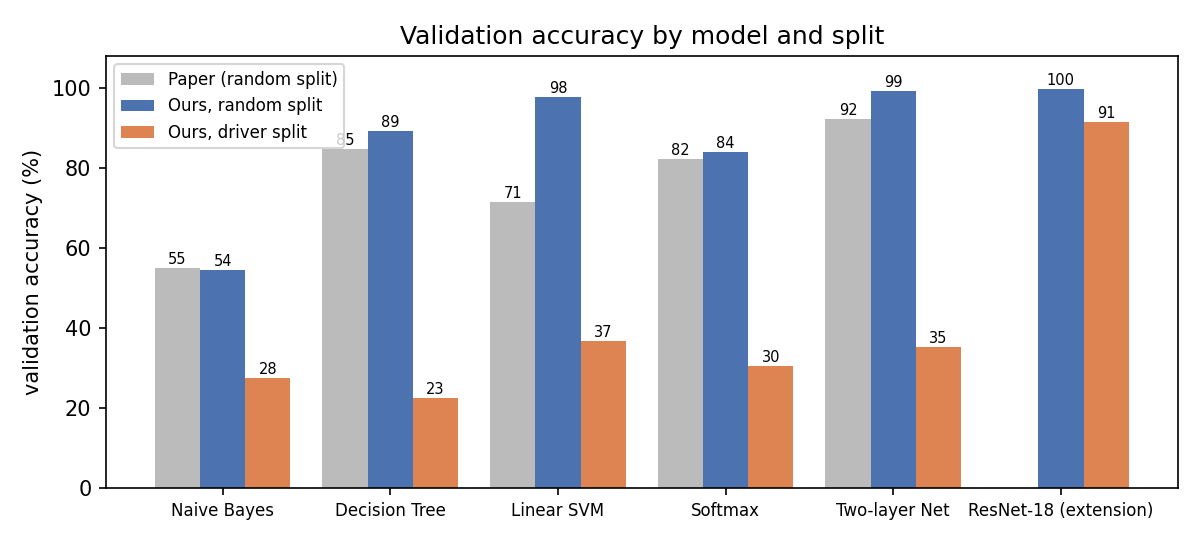

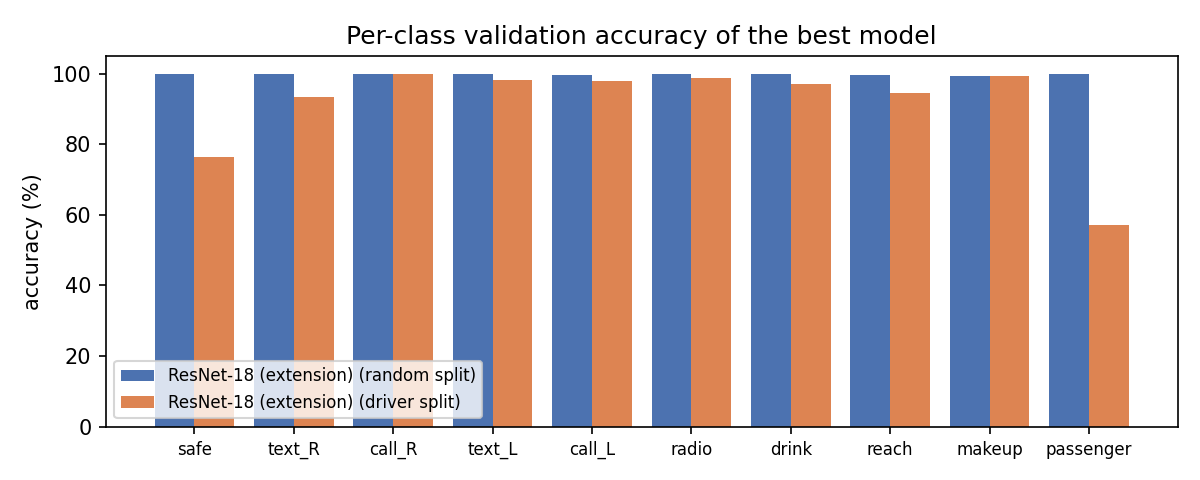

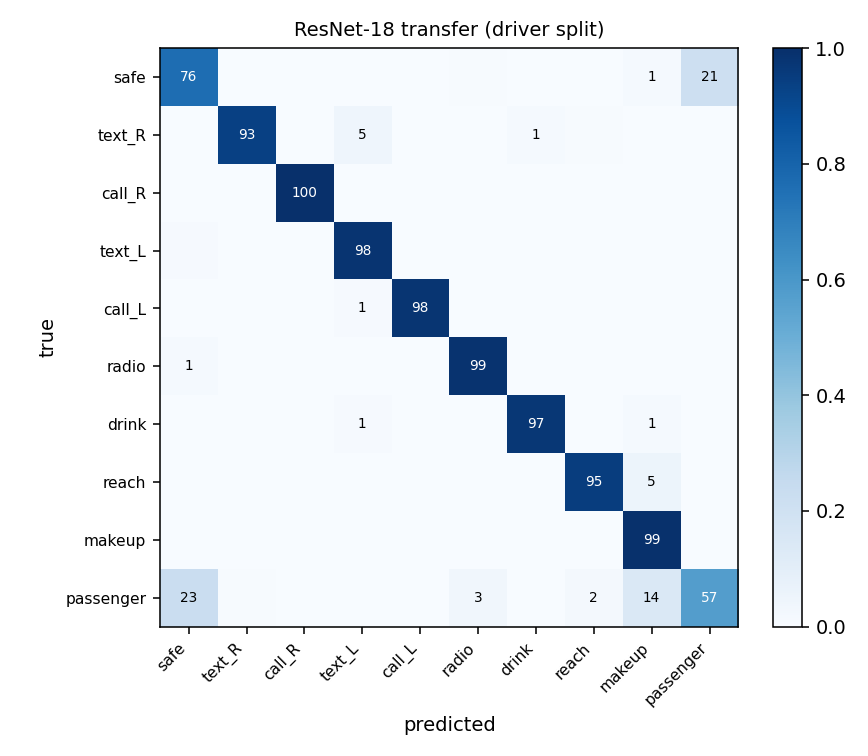

In [2]:
from IPython.display import Image, display
GITHUB_USER = 'sahanaks1011'    # Sahana's GitHub username (the repo owner)

OUT = '/content/drive/MyDrive/DDD_Team7/outputs/results'
needed = [m + '_' + s for m in ['linear_svm', 'softmax', 'two_layer_net', 'naive_bayes', 'decision_tree', 'resnet18_transfer'] for s in ['random', 'driver']]
missing = [n for n in needed if not os.path.exists(f'{OUT}/{n}.json')]
print('Missing results:', missing if missing else 'none, all 12 present')
if GITHUB_USER == 'YOUR_USERNAME':
    print('NOTE: GITHUB_USER is still the placeholder, so the repo link in the PDF will be wrong. Set it and rerun this cell.')
!python -m src.report
!python -m src.make_writeup --repo_url https://github.com/{GITHUB_USER}/distracted-driver-detection
print(open(f'{OUT}/summary.md').read())
for f in ['accuracy_comparison', 'per_class_best', 'cm_resnet18_transfer_driver']:
    p = f'{OUT}/figures/{f}.png'
    if os.path.exists(p):
        display(Image(p))
    else:
        print('figure not found yet:', f)

# Live demo (review day)
Open this notebook, run **Step 1 only**, then run the cells below. No dataset download and no training needed.

/content/drive/MyDrive/DDD_Team7/outputs/demo_images/c0_img_1617.jpg   [true: c0 Safe driving]
    c0 Safe driving             78.4%
    c2 Phone call (right)        5.0%
    c8 Hair and makeup           3.0%
/content/drive/MyDrive/DDD_Team7/outputs/demo_images/c0_img_76704.jpg   [true: c0 Safe driving]
    c0 Safe driving             57.8%
    c4 Phone call (left)        13.2%
    c6 Drinking                  6.7%
/content/drive/MyDrive/DDD_Team7/outputs/demo_images/c1_img_46531.jpg   [true: c1 Texting (right)]
    c1 Texting (right)          79.6%
    c3 Texting (left)            4.0%
    c5 Operating radio           2.8%
/content/drive/MyDrive/DDD_Team7/outputs/demo_images/c1_img_46972.jpg   [true: c1 Texting (right)]
    c1 Texting (right)          75.6%
    c6 Drinking                  6.0%
    c0 Safe driving              3.5%
/content/drive/MyDrive/DDD_Team7/outputs/demo_images/c2_img_16663.jpg   [true: c2 Phone call (right)]
    c2 Phone call (right)       84.7%
    c9 Talking 

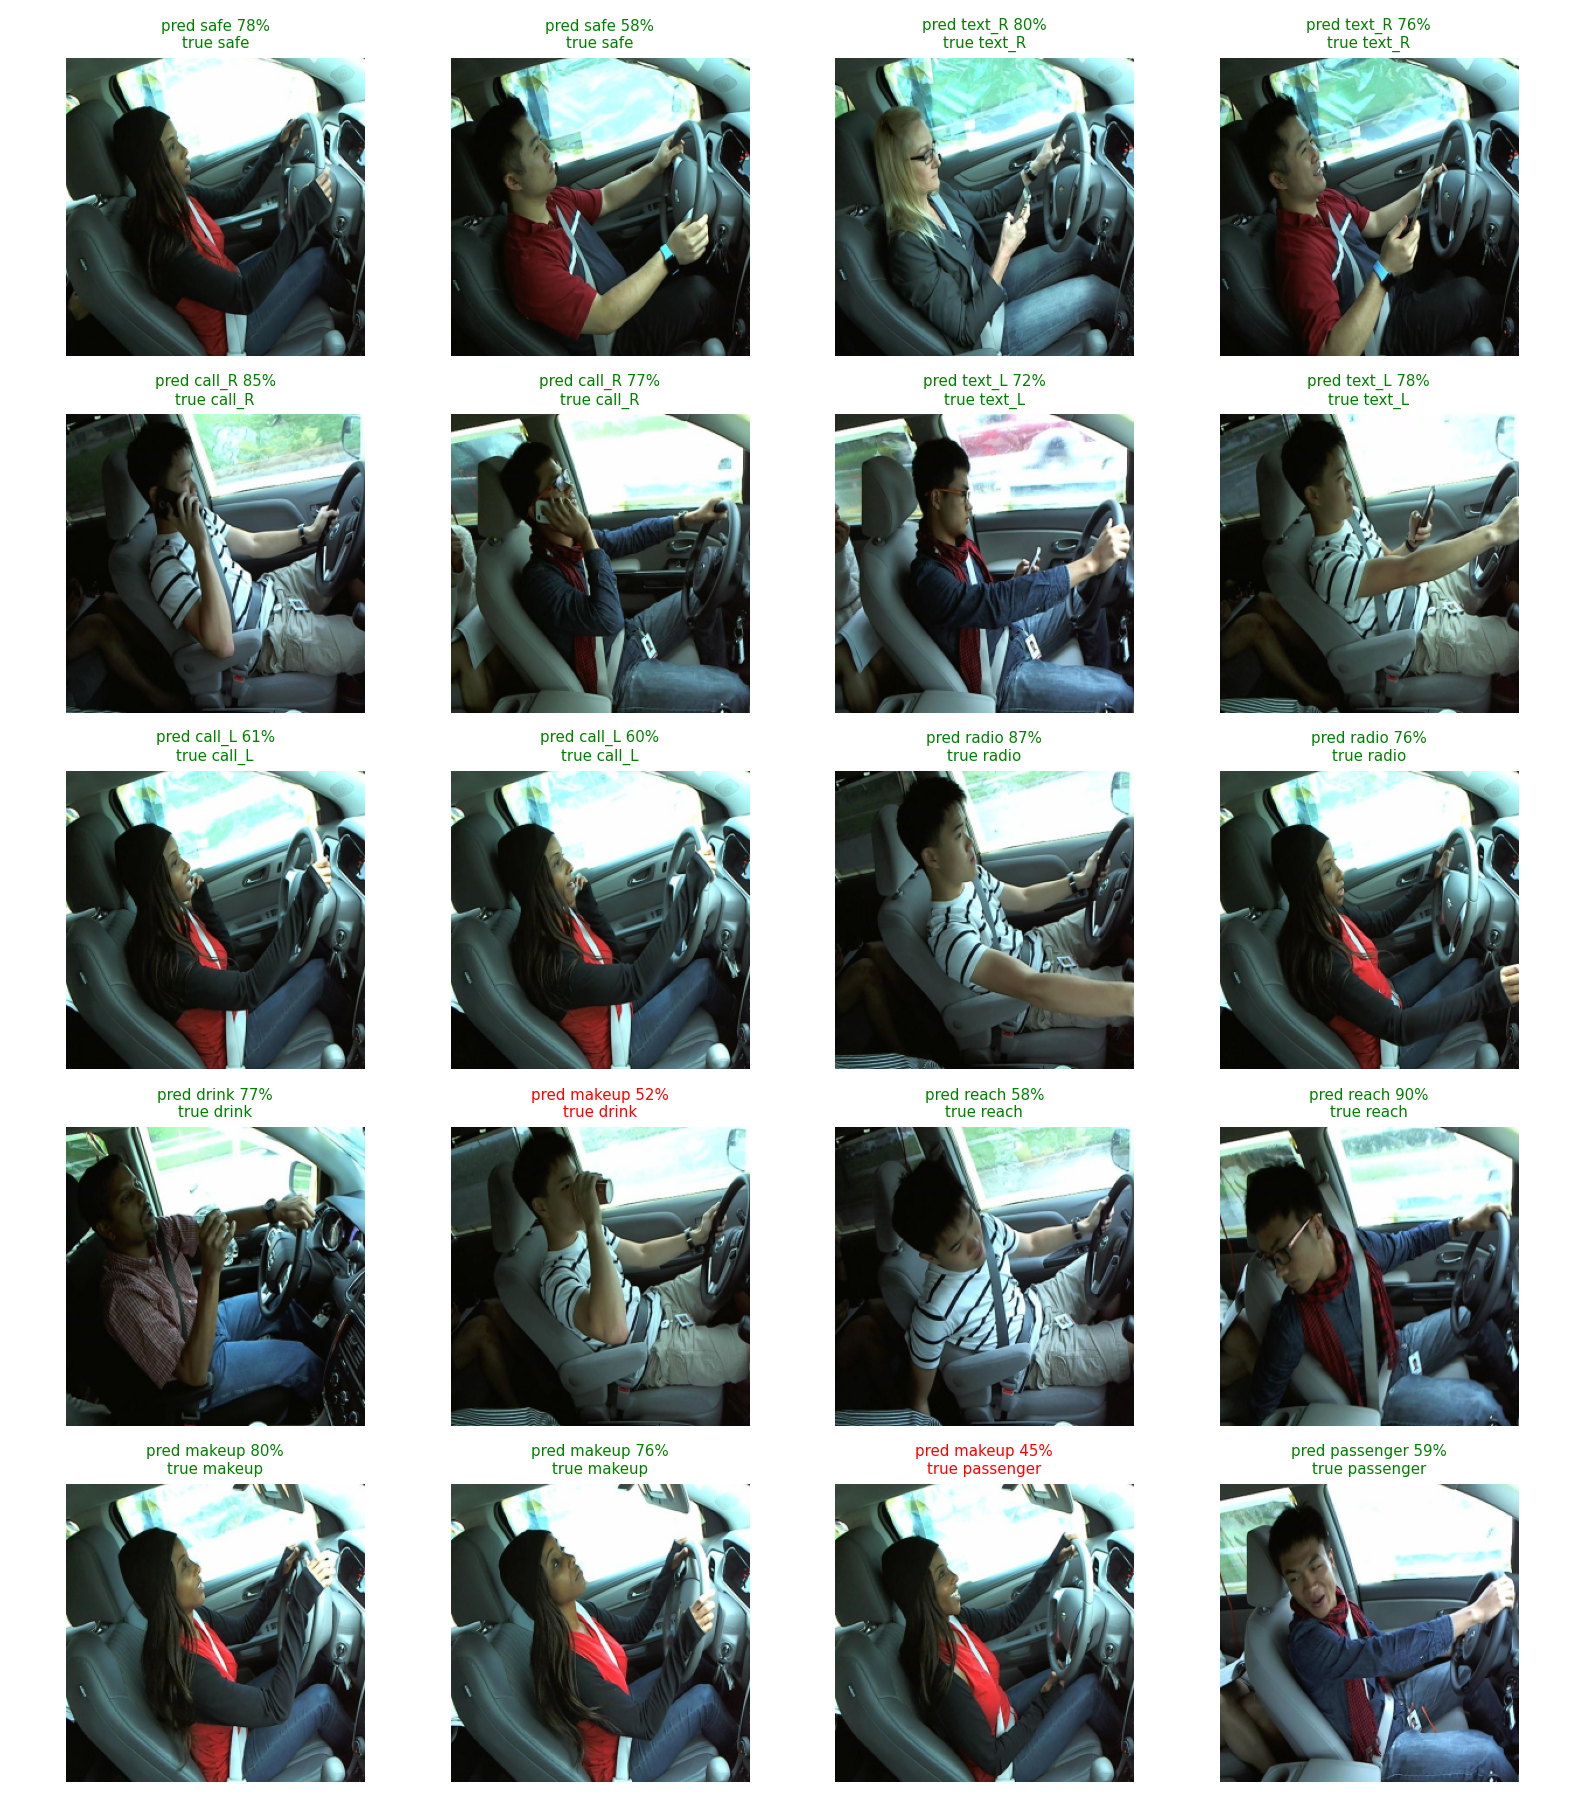

In [ ]:
from IPython.display import Image, display
!python -m src.predict --folder demo --model cnn --split driver
display(Image('/content/drive/MyDrive/DDD_Team7/outputs/results/figures/demo_cnn_driver.png'))

/content/drive/MyDrive/DDD_Team7/outputs/demo_images/c0_img_1617.jpg   [true: c0 Safe driving]
    c2 Phone call (right)       85.8%
    c0 Safe driving              3.8%
    c5 Operating radio           3.4%
/content/drive/MyDrive/DDD_Team7/outputs/demo_images/c0_img_76704.jpg   [true: c0 Safe driving]
    c4 Phone call (left)        62.1%
    c0 Safe driving             16.2%
    c9 Talking to passenger     10.2%
/content/drive/MyDrive/DDD_Team7/outputs/demo_images/c1_img_46531.jpg   [true: c1 Texting (right)]
    c9 Talking to passenger     41.8%
    c1 Texting (right)          23.6%
    c5 Operating radio          14.5%
/content/drive/MyDrive/DDD_Team7/outputs/demo_images/c1_img_46972.jpg   [true: c1 Texting (right)]
    c4 Phone call (left)        32.1%
    c8 Hair and makeup          22.3%
    c1 Texting (right)          14.0%
/content/drive/MyDrive/DDD_Team7/outputs/demo_images/c2_img_16663.jpg   [true: c2 Phone call (right)]
    c9 Talking to passenger     46.4%
    c0 Safe dri

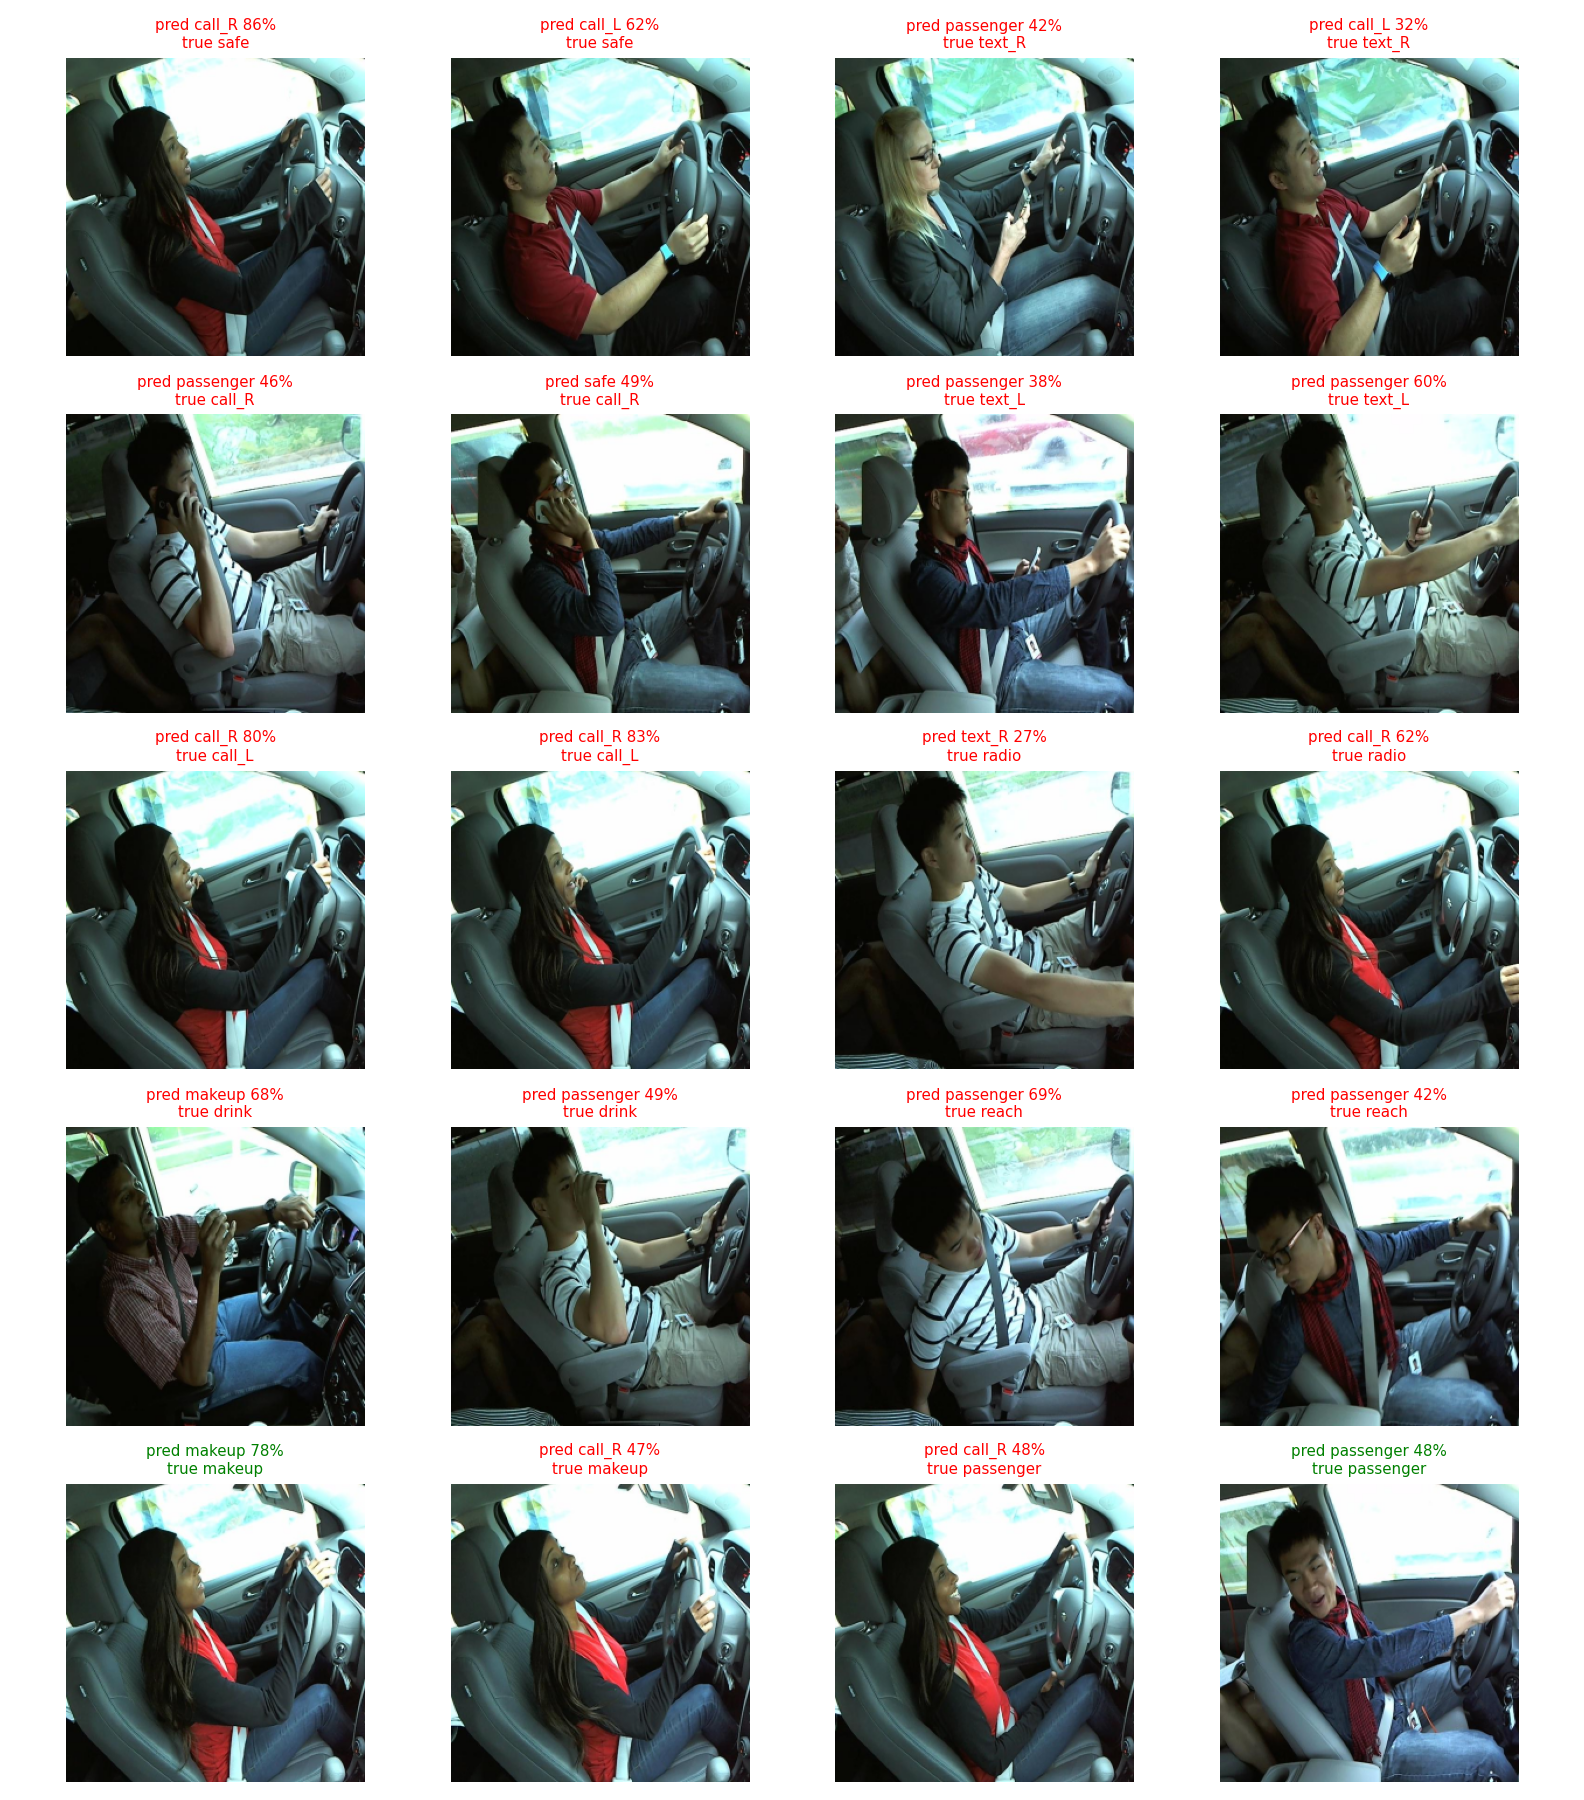

In [ ]:
!python -m src.predict --folder demo --model nn --split driver
display(Image('/content/drive/MyDrive/DDD_Team7/outputs/results/figures/demo_nn_driver.png'))

In [ ]:
# Optional: web page where you upload any photo (gives a public link, stop the cell when done)
!pip -q install gradio
!python app.py

* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://12707959a4ddff174d.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
